In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt
import clip
import numpy as np

from pibisa import PibisaConfig, PibisaAtt
from PIL import Image
from models import ResNET_emb
from utils import unnormalize

In [2]:
if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

transform = torchvision.transforms.Compose([torchvision.transforms.Resize((224,224)),
                            torchvision.transforms.ToTensor()])

In [3]:
pil_img1 = Image.open('../test_images/Black1.JPEG').convert('RGB')
pil_img2 = Image.open('../test_images/Black2.JPEG').convert('RGB')

img1 = transform(pil_img1)
img2 = transform(pil_img2)

x1 = torchvision.transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(img1)
x2 = torchvision.transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(img2)

x1 = x1[None,...].to(device)
x2 = x2[None,...].to(device)

In [4]:
# model, preprocess = clip.load("ViT-B/16", device=device)
# model.eval()

In [5]:
model = ResNET_emb()

In [6]:
config = PibisaConfig(numberMasks=2, epochs=15)
pibisa = PibisaAtt(model.forward, config)

In [7]:
saliencyMap = pibisa.compute_attribution(queryInput=x1, targetEmb=model.forward(x2))

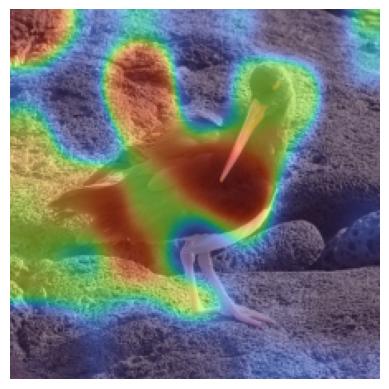

In [8]:
plt.imshow(unnormalize(x1))
plt.imshow(saliencyMap.squeeze(), cmap='turbo', alpha=0.5)
plt.axis('off')
plt.show()

In [9]:
salList = [saliencyMap,saliencyMap]

In [10]:
binarySal = create_sal_masks(saliencyList=salList)

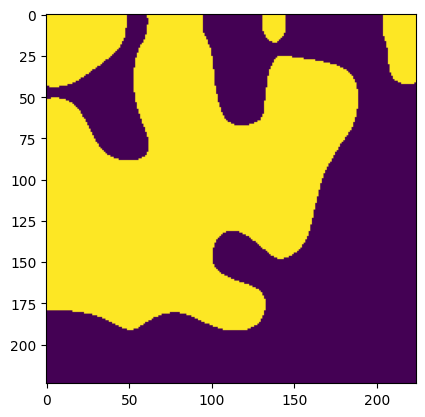

In [12]:
plt.imshow(np.squeeze(binarySal[1]))

In [17]:
x1.device

device(type='cpu')